# Random Forest

## Objectives
The objective of this notebook is to fit a random forest to the house prices with scikit-learn, tune it by 5-fold cross-validation, and submit it. The theory of trees, bagging and random forests is in the tree models notebook, and the lasso of the regularisation notebook is the reference. The forest needs no standardising or logs, so it uses the cleaned and encoded columns as they are. Sections 1 to 3 set up the features, a baseline and the hyperparameters, sections 4 and 5 choose the number of trees and tune the settings, and sections 6 and 7 look at the fitted model and submit it.

## 1. Features
A forest needs no standardising or log of the columns, because a split only uses the order of the values, and collinear columns are not a problem. So we use the output of `clean` and `engineer`, with every column and none of the logs or squares, and the target is $\log(\text{SalePrice})$. The cleaning and the encoding are refitted on the fitting houses of each fold, as in the regularisation notebook, so that no validation house influences them.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold

from src.data import load_train, load_test
from src.engineering import engineer
from src.features import clean
from src.submission import save_submission

train, test = load_train(), load_test()
folds = KFold(5, shuffle=True, random_state=0)


def make_features(fit_raw, df_raw):
    # Clean and encode with the fill values and levels of the fitting houses only.
    fit_clean, df_clean = clean(fit_raw, fit_raw), clean(df_raw, fit_raw)
    return fit_clean, df_clean, engineer(fit_clean, fit_clean), engineer(df_clean, fit_clean)


# The features and the log price of the fitting and validation houses of each fold.
fold_data, fold_columns = [], []
for fit_index, validation_index in folds.split(train):
    fit_clean, validation_clean, fit_features, validation_features = make_features(train.iloc[fit_index], train.iloc[validation_index])
    fold_columns.append(fit_features.columns)
    fold_data.append((fit_features.to_numpy(dtype=float), np.log(fit_clean["SalePrice"]).to_numpy(), validation_features.to_numpy(dtype=float), np.log(validation_clean["SalePrice"]).to_numpy()))
weights = np.array([len(data[3]) for data in fold_data]) / sum(len(data[3]) for data in fold_data)


def cv_rmse(make_model):
    # The RMSE of the log price over all the houses, and on each validation fold.
    mse = np.array([np.mean((y_val - make_model().fit(X_fit, y_fit).predict(X_val)) ** 2) for X_fit, y_fit, X_val, y_val in fold_data])
    return np.sqrt(weights @ mse), np.sqrt(mse)


# All the train houses, and the test houses encoded with the levels of train.
fit_clean, test_clean, features, test_features = make_features(train, test)
X, y, X_test = features.to_numpy(dtype=float), np.log(fit_clean["SalePrice"]).to_numpy(), test_features.to_numpy(dtype=float)
print("Train houses and columns:", X.shape, ", test:", X_test.shape, ", same columns:", list(features.columns) == list(test_features.columns))

Train houses and columns: (1458, 177) , test: (1459, 177) , same columns: True


## 2. Baseline Model
We first fit the forest with the default settings of scikit-learn, to have something to improve on. We score it two ways: with the 5-fold cross-validation, and with the out-of-bag error, which comes free from the trees that did not see each house. We ask:
- What are the default settings, and what is the error of the log price on unseen houses?
- How well does the out-of-bag error agree with the cross-validated error?

In [2]:
defaults = RandomForestRegressor(n_jobs=-1, random_state=0)
print({name: value for name, value in defaults.get_params().items() if name in ["n_estimators", "max_features", "min_samples_leaf", "max_depth", "bootstrap"]})

overall, per_fold = cv_rmse(lambda: RandomForestRegressor(n_jobs=-1, random_state=0))
oob = RandomForestRegressor(oob_score=True, n_jobs=-1, random_state=0).fit(X, y)
print(f"5-fold CV RMSE of the log price: {overall:.4f}, folds {np.round(per_fold, 4)}")
print(f"Out-of-bag RMSE: {np.sqrt(np.mean((y - oob.oob_prediction_) ** 2)):.4f}")

{'bootstrap': True, 'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 100}
5-fold CV RMSE of the log price: 0.1377, folds [0.1303 0.1329 0.167  0.1307 0.1234]
Out-of-bag RMSE: 0.1350


##### Findings:
- The defaults are 100 trees, all the columns at each split, 1 house per leaf and no limit on the depth.
- The cross-validated RMSE of the log price is 0.1377. The folds run from 0.1234 to 0.1670, and fold 3 is the hardest.
- The out-of-bag RMSE is 0.1350, which is within 0.003 of the cross-validated one, so it is a good free estimate of the error on unseen houses.
- This is worse than the lasso, which had 0.1115 on the same folds.

## 3. Hyperparameters
The settings of the forest, as in the tree models notebook, are:
- `n_estimators` is the number of trees. More trees never overfit, so we take enough that the error has levelled off.
- `max_features` is the share of the columns tried at each split. A smaller share makes the trees more different, which lowers the correlation between them, but each tree is weaker.
- `min_samples_leaf` is the least number of houses in a leaf. A larger value gives smoother trees, with more bias and less variance.
- `max_depth` limits the number of questions in a row. We leave it unlimited and use `min_samples_leaf` to limit the trees instead.
- `max_samples` is the size of each bootstrap sample, and we keep the default of $n$.

We do not prune the trees after growing them. Pruning reduces the variance of a single tree, and the forest does that by averaging, so the trees are grown deep. The two limits above are the only control of the depth we use.

## 4. Number of Trees
The error of an average of trees falls and then levels off as trees are added. We fit one large forest, and compute its out-of-bag error after each tree is added, using for each house only the trees so far that did not see it. We ask:
- How many trees are needed before the error stops improving?

                   10      25      50      100     200     300     500     1000
Out-of-bag RMSE  0.1569  0.1377  0.1322  0.1301  0.1292  0.1288  0.1284  0.1279


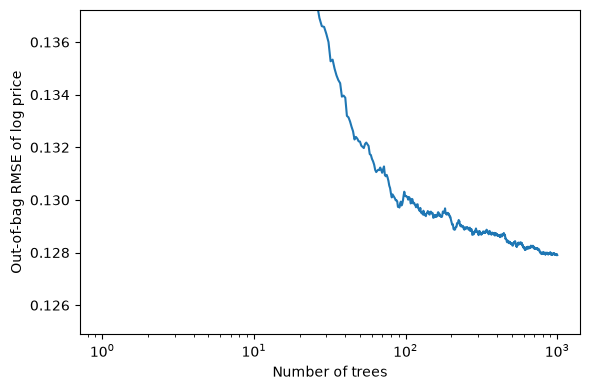

In [3]:
# One forest of 1000 trees, with a third of the columns at each split.
forest = RandomForestRegressor(1000, max_features=1 / 3, n_jobs=-1, random_state=0).fit(X, y)
total, count, curve = np.zeros(len(y)), np.zeros(len(y)), []
for tree, sample in zip(forest.estimators_, forest.estimators_samples_):
    # Add the prediction of this tree for the houses it did not see.
    left_out = np.setdiff1d(np.arange(len(y)), sample)
    total[left_out] += tree.predict(X[left_out])
    count[left_out] += 1
    seen = count > 0
    curve.append(np.sqrt(np.mean((y[seen] - total[seen] / count[seen]) ** 2)))
curve = np.array(curve)
print(pd.Series({n: curve[n - 1] for n in [10, 25, 50, 100, 200, 300, 500, 1000]}, name="Out-of-bag RMSE").round(4).to_frame().T.to_string())

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, 1001), curve)
plt.xscale("log")
plt.ylim(curve[-1] - 0.003, curve[49] + 0.005)
plt.xlabel("Number of trees")
plt.ylabel("Out-of-bag RMSE of log price")
plt.tight_layout()
plt.show()

##### Findings:
- The out-of-bag RMSE falls fast and then levels off: 0.1569 with 10 trees, 0.1377 with 25, 0.1322 with 50, 0.1301 with 100, 0.1292 with 200, 0.1288 with 300, 0.1284 with 500 and 0.1279 with 1000.
- With 10 trees each house is predicted by only a few trees, so the early values are noisy. Going from 300 to 1000 trees gains 0.0009.

##### Decision:
Use 300 trees for the tuning, and 500 for the final fit.

## 5. Tuning
We tune the share of columns at each split and the minimum houses per leaf, with 300 trees and the same 5-fold cross-validation. With two settings, a grid is small enough. The grids are:
- A share of columns of 0.1, 0.2, a third, 0.5, 0.7 or 1.
- A minimum of 1, 2, 3, 5 or 10 houses per leaf.

We ask:
- Which settings give the lowest cross-validated error, and by how much do they beat the defaults?
- How sensitive is the error to each setting?
- How much do the folds disagree?

Houses per leaf,1,2,3,5,10
Share of columns,,,,,
0.10,0.1325,0.1345,0.1366,0.1407,0.1492
0.20,0.1304,0.1314,0.1328,0.1357,0.1428
0.33,0.1298,0.1306,0.1319,0.1343,0.1400
0.50,0.1318,0.1317,0.1328,0.1349,0.1403
0.70,0.1340,0.1337,0.1344,0.1365,0.1421
1.00,0.1373,0.1372,0.1373,0.1391,0.1448


Best: 0.33 of the columns and 1 houses per leaf, CV RMSE 0.1298, against 0.1377 for the defaults
Folds at the best settings: [0.1214 0.1173 0.1643 0.1225 0.1174] , defaults: [0.1303 0.1329 0.167  0.1307 0.1234]


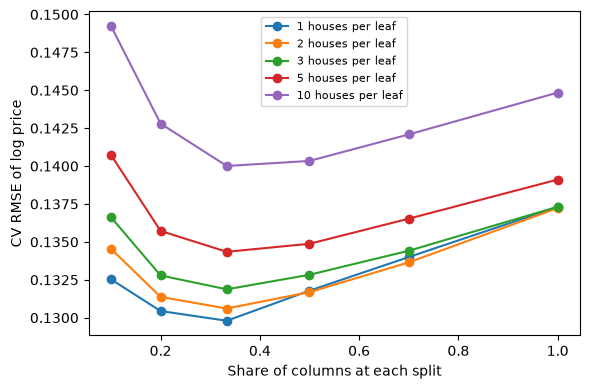

In [4]:
SHARES = [0.1, 0.2, 1 / 3, 0.5, 0.7, 1.0]
LEAVES = [1, 2, 3, 5, 10]
grid, fold_grid = {}, {}
for share in SHARES:
    for leaf in LEAVES:
        grid[(share, leaf)], fold_grid[(share, leaf)] = cv_rmse(lambda: RandomForestRegressor(300, max_features=share, min_samples_leaf=leaf, n_jobs=-1, random_state=0))
table = pd.DataFrame({leaf: [grid[(share, leaf)] for share in SHARES] for leaf in LEAVES}, index=[f"{share:.2f}" for share in SHARES])
table.index.name, table.columns.name = "Share of columns", "Houses per leaf"
display(table.round(4))

best_share, best_leaf = min(grid, key=grid.get)
print(f"Best: {best_share:.2f} of the columns and {best_leaf} houses per leaf, CV RMSE {grid[(best_share, best_leaf)]:.4f}, against {overall:.4f} for the defaults")
print("Folds at the best settings:", np.round(fold_grid[(best_share, best_leaf)], 4), ", defaults:", np.round(per_fold, 4))

plt.figure(figsize=(6, 4))
for leaf in LEAVES:
    plt.plot(SHARES, [grid[(share, leaf)] for share in SHARES], marker="o", label=f"{leaf} houses per leaf")
plt.xlabel("Share of columns at each split")
plt.ylabel("CV RMSE of log price")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

##### Findings:
- The best settings are a third of the columns at each split and 1 house per leaf, with a cross-validated RMSE of 0.1298. That is 0.0079 lower than the defaults (0.1377), and it is lower in every fold, by 0.0089, 0.0156, 0.0027, 0.0082 and 0.0060.
- The share of columns matters: with all the columns the error is 0.1373, and with a third it is 0.1298. A share of 0.1 gives 0.1325, so the best is in the middle of the range, and the share of 0.2 (0.1304) and 0.5 (0.1318) are close.
- A larger minimum of houses per leaf makes the error worse at every share. At a third of the columns it goes 0.1298, 0.1306, 0.1319, 0.1343 and 0.1400 for 1, 2, 3, 5 and 10 houses. So the deep trees are best, as the theory says, and 1 is the smallest value possible.
- The folds disagree on the level, from 0.1173 to 0.1643, and fold 3 is again the hardest, but the folds agree on the ranking of the settings.

##### Decision:
Use a third of the columns and 1 house per leaf. The cross-validated error of the best settings is slightly optimistic, because we chose the best of 30 on the same folds.

## 6. The Fitted Model
We refit the forest on all the train houses at the best settings, with 500 trees. The importance of a column is judged two ways. The built-in importance is the total reduction of the squared error from the splits on a column, which tends to favour columns with many values. The permutation importance is the rise in error on unseen houses when the values of a column are shuffled, which we measure on the validation houses of the first fold, using a forest fitted on that fold's fitting houses. We ask:
- How large is the gap between the error on the fitting houses, the out-of-bag error and the cross-validated error?
- Which columns matter most, by each measure?
- How does the forest treat the extrapolated Id 2550?

In [5]:
final = RandomForestRegressor(500, max_features=best_share, min_samples_leaf=best_leaf, oob_score=True, n_jobs=-1, random_state=0).fit(X, y)
summary = pd.Series(
    {
        "In-sample RMSE": np.sqrt(np.mean((y - final.predict(X)) ** 2)),
        "Out-of-bag RMSE": np.sqrt(np.mean((y - final.oob_prediction_) ** 2)),
        "CV RMSE": grid[(best_share, best_leaf)],
    }
)
print(summary.round(4).to_string())

# Importance: built in, and by permutation on the validation houses of the first fold.
X_fit, y_fit, X_val, y_val = fold_data[0]
fold_forest = RandomForestRegressor(500, max_features=best_share, min_samples_leaf=best_leaf, n_jobs=-1, random_state=0).fit(X_fit, y_fit)
permutation = permutation_importance(fold_forest, X_val, y_val, scoring="neg_mean_squared_error", n_repeats=10, n_jobs=-1, random_state=0)
# The first fold has fewer columns than all of train, because rare levels are grouped on the fitting houses of each fold.
built_in = pd.Series(final.feature_importances_, index=features.columns).sort_values(ascending=False)
by_permutation = pd.Series(permutation.importances_mean, index=fold_columns[0]).sort_values(ascending=False)
print("Built-in importance, all of train:")
print(built_in.head(10).round(4).to_string())
print()
print("Permutation importance, rise in MSE on the validation houses of the first fold:")
print(by_permutation.head(10).round(4).to_string())

# The predicted prices of the test houses.
prices = pd.Series(np.exp(final.predict(X_test)), index=test_features.index)
print(f"Predicted price: lowest {prices.min():,.0f}, median {prices.median():,.0f}, highest {prices.max():,.0f}, Id 2550 {prices[2550]:,.0f}")
print(f"Highest train price: {np.exp(y).max():,.0f}")

In-sample RMSE     0.0474
Out-of-bag RMSE    0.1284
CV RMSE            0.1298
Built-in importance, all of train:
TotalSF           0.2575
OverallQual       0.2124
GrLivArea         0.0662
ExterQual         0.0601
HouseAge          0.0523
KitchenQual       0.0392
TotalBathrooms    0.0305
GarageArea        0.0298
GarageCars        0.0251
BsmtQual          0.0170

Permutation importance, rise in MSE on the validation houses of the first fold:
TotalSF        0.0298
OverallQual    0.0118
GrLivArea      0.0036
KitchenQual    0.0013
HouseAge       0.0012
ExterQual      0.0012
BsmtFinSF1     0.0009
BsmtQual       0.0008
OverallCond    0.0007
RemodelAge     0.0007
Predicted price: lowest 56,755, median 155,879, highest 568,146, Id 2550 568,146
Highest train price: 755,000


##### Findings:
- The in-sample RMSE is 0.0474, against 0.1284 out-of-bag and 0.1298 cross-validated. The deep trees fit the train houses closely, so the in-sample error says little about new houses. The out-of-bag error agrees with the cross-validated error to within 0.0014.
- Both measures of importance rank the same columns first. The built-in importance is highest for `TotalSF` (0.258) and `OverallQual` (0.212), then `GrLivArea` (0.066), `ExterQual` (0.060) and `HouseAge` (0.052). By permutation, `TotalSF` (0.0298), `OverallQual` (0.0118) and `GrLivArea` (0.0036) are first, and `KitchenQual`, `HouseAge` and `ExterQual` follow at about 0.001.
- `TotalSF` contains `GrLivArea`, so the two share the importance of the size, and the importance of either alone should not be read too closely.
- The forest does not extrapolate. The prediction for Id 2550 is 568,000, which is also the highest of all the test predictions, and it is below the highest train price (755,000). The lasso predicted 731,000 for the same house.

## 7. Submission
The forest predicts the log price of the test houses, and the prediction is turned back into a price with the exponential, as in the other notebooks. The file is saved as `forest_v01.csv` by `save_submission`, which checks it against the sample file.

In [6]:
print("Saved:", save_submission(test_features.index, prices.to_numpy(), "forest", 1))

Saved: ../submissions/forest_v01.csv
